(course-enzyme-geometric-transformations)=

# Path B - Module 46: Geometric Transformations (Space)

Molecular systems in a simulation box are often oriented randomly. For a technical report or for specific analysis (like measuring diffusion across a channel or orientation in a reactor), you need to control the position and rotation of your molecules manually.

In this module, you will learn to use the geometric engine of MolSysMT to arrange your engineered PETase in 3D space.

In [1]:
import molsysmt as msm
from molsysmt import systems
import numpy as np

# Load our complex
petase = msm.convert('pdb:6EQE', to_form='molsysmt.MolSys', selection='molecule_type=="protein"')
# RDKit supplies one deterministic illustrative 3D conformer.
from rdkit import Chem
from rdkit.Chem import AllChem

bhet_rdkit = msm.convert('smiles:C1=CC(=CC=C1C(=O)OCCO)C(=O)OCCO', to_form='rdkit.Mol')
bhet_rdkit = Chem.AddHs(bhet_rdkit)
assert AllChem.EmbedMolecule(bhet_rdkit, randomSeed=7) == 0
bhet = msm.convert(bhet_rdkit, to_form='molsysmt.MolSys')
molsys = msm.merge([petase, bhet])
# Keep the protein and newly added substrate populations explicit.
n_protein_atoms = msm.get(petase, n_atoms=True)
protein_atom_indices = list(range(n_protein_atoms))
bhet_atom_indices = list(range(n_protein_atoms, msm.get(molsys, n_atoms=True)))


## 1. Centering at the Origin
To simplify your coordinates, it is always a good idea to center the main enzyme at the origin (0,0,0).
Only `selection` moves. Its center is the default source center; the
substrate remains unchanged. To translate the whole complex using the protein
as an anchor instead, use `selection='all'` and
`source_center_selection=protein_atom_indices`. Use `target_coordinates`
or the initial center of `target_center_selection` to choose another destination.
See the {ref}`centering tutorial <Tutorial_Center>`.

The setup uses RDKit to generate one reproducible BHET conformer; SMILES
alone defines chemistry and supplies no 3D pose. This illustrative placement
is not a predicted binding pose or an energy-minimized structure.


In [2]:
# Center the protein at [0,0,0]
msm.structure.center(molsys, selection=protein_atom_indices, in_place=True)

new_center = msm.structure.get_center(molsys, selection=protein_atom_indices)
print(f"Enzyme center after transformation: {new_center}")
assert np.allclose(msm.pyunitwizard.get_value(new_center, to_unit="nm"), 0.0)


Enzyme center after transformation: [[[-8.650681287063589e-16 -8.032277771778133e-16 -6.433719201279673e-16]]] nanometer


## 2. Manual Translation
Let's move the BHET substrate 3.0 nm away from the protein to simulate a "pre-binding" state.

In [3]:
# Move the substrate by a vector [3.0, 0.0, 0.0] nm
shift_vector = np.array([3.0, 0.0, 0.0]) * msm.pyunitwizard.unit('nm')
msm.structure.translate(molsys, selection=bhet_atom_indices, translation=shift_vector, in_place=True)

print("BHET substrate translated 3nm along the X-axis.")

BHET substrate translated 3nm along the X-axis.


## 3. Rotating for Posing
You can rotate a molecule around its own center or around an arbitrary axis. This is critical to explore how the plastic monomer enters the active site.

BHET substrate flipped 180 degrees.


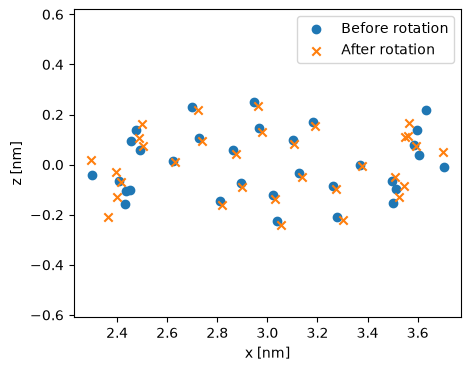

In [4]:
# Rotate the BHET 180 degrees around the Y axis and its own center
rotation = np.diag([-1.0, 1.0, -1.0])
rotation_center = msm.structure.get_center(molsys, selection=bhet_atom_indices)
before_rotation = msm.pyunitwizard.get_value(
    msm.get(molsys, element='atom', selection=bhet_atom_indices, coordinates=True),
    to_unit='nm').copy()
msm.structure.rotate(
    molsys, selection=bhet_atom_indices, rotation=rotation,
    rotation_center=rotation_center, in_place=True
)

print("BHET substrate flipped 180 degrees.")
# Compare the actual pose before and after the proper rotation.
import matplotlib.pyplot as plt

after_rotation = msm.pyunitwizard.get_value(
    msm.get(molsys, element='atom', selection=bhet_atom_indices, coordinates=True),
    to_unit='nm')
np.testing.assert_allclose(
    np.linalg.norm(before_rotation[:, :, None] - before_rotation[:, None, :], axis=-1),
    np.linalg.norm(after_rotation[:, :, None] - after_rotation[:, None, :], axis=-1),
    atol=1e-12)
plt.figure(figsize=(5, 4))
plt.scatter(before_rotation[0, :, 0], before_rotation[0, :, 2], label='Before rotation')
plt.scatter(after_rotation[0, :, 0], after_rotation[0, :, 2], label='After rotation', marker='x')
plt.xlabel('x [nm]')
plt.ylabel('z [nm]')
plt.axis('equal')
plt.legend()
plt.show()

--- 

## 🏁 END OF PHASE 5: THE PHYSICS LAB

**Congratulations!** You have mastered the environment and the dynamics of your biocatalyst. You have:
1.  **Managed Boxes** and **PBC**.
2.  **Wrapped** and **Unwrapped** coordinates.
3.  **Calculated Energies** and **Forces**.
4.  **Minimized** and **Simulated** at industrial temperatures in OpenMM.
5.  **Translated**, **Rotated**, and **Centered** your components in space.

Now, we enter the final stretch. In **Phase 6: Pipeline Developer**, we will learn how to handle Big Data trajectories and automate your engineering pipeline.